# Fluxes at Earth, one effect at a time

This notebook computes the flux of high-energy astrophysical neutrinos at Earth when they feel a new force, and turns
on its effects one at a time. Each family of models we test has two examples:

1. **The dark portal**: a 10 MeV mediator (absorption on the relic neutrinos, the potential inside the Earth), and a
   $10^{-10}$ eV one (decay).
2. **$L_e - L_\mu$**: a $10^{-20}$ eV mediator (the Sun's potential, decay), and a $10^{-2}$ eV one (decay,
   scatterings on the relic neutrinos).
3. **Secret interactions**: a 10 MeV scalar (absorption on the relic neutrinos), and a 1 meV one (decay).

Each example has two figures. The first shows the spectrum and the flavor fractions against energy; under each panel,
a shorter one shows the relative change from the previous step, that is, the effect of the term that step adds. The
second places the flavor composition, averaged over energy, in the flavor triangle, next to IceCube's measurement.

Section 5 then follows the $L_e - L_\mu$ example along the trip, stop by stop, at two mediator masses.

To run it all (about 3 minutes on 4 cores):

    jupyter nbconvert --to notebook --execute --inplace notebooks/fluxes_at_earth.ipynb

## The models

- **The dark portal.** The mediator couples to a sterile neutrino, which mixes with the active ones ($u_e$, $u_\mu$,
  $u_\tau$), and to matter through a small mixing with the Z boson ($\epsilon'$).
- **$L_e - L_\mu$.** The mediator is the gauge boson of electron number minus muon number. It couples to $\nu_e$ and
  $\nu_\mu$ with charges $+1$ and $-1$, and to electrons.
- **Secret interactions.** The mediator couples only to neutrinos, so it makes no potential.

We write the coupling $g_D$ for the dark portal, $g'$ for the gauge models and $g$ for secret interactions.

## The effects

The neutrinos are emitted up to redshift 4 with pion-decay flavors, $(f_e, f_\mu, f_\tau) = (1/3, 2/3, 0)$, and
followed to IceCube. Each step in the examples adds one effect of the new force:

- **The potential.** Matter within the mediator's range, $1/M$, sources a potential on the neutrinos: electrons for
  $L_e - L_\mu$, neutrons for the dark portal. The neutrinos then travel as the eigenstates of the vacuum term plus
  the potential, instead of the mass states. Where the potential dominates and turns on slowly, each mass state turns
  smoothly into one of the potential's eigenstates.
- **Collisions with the relic neutrinos (resonant absorption).** A high-energy neutrino and a relic neutrino of mass
  $m_r$ form the mediator on resonance, when the neutrino's energy is $M^2/2m_r$. The neutrino is absorbed, and the
  mediator decays into a neutrino and an antineutrino of lower energies, the secondaries. This matters for MeV
  mediators.
- **The other collision channels.** Besides the resonance, the two neutrinos can exchange the mediator, and they can
  produce two mediators. The secret-interactions example switches these on separately.
- **Decay.** A heavier neutrino emits the mediator and becomes a lighter one, if the mediator is lighter than their
  mass difference. The daughter keeps part of the energy and the mediator takes the rest. Decays are slower at higher
  energies, because of time dilation.
- **Soft scatterings on the relic neutrinos.** Below 1 keV, a high-energy neutrino can exchange the mediator with a
  relic neutrino and jump to another state at nearly the same energy. When the relic changes its mass state, the
  neutrino loses a little energy. The rate grows as $g'^4/M^2$, so this needs large couplings.
- **The relics' thermal motion.** The relics are not at rest: their temperature today is $1.7 \times 10^{-4}$ eV.
  For the dark portal and the gauge models, the resonance always includes their motion, and this step adds it to every
  other collision. For secret interactions, the relics are at rest by default, and this step adds their motion
  everywhere.

The equations are in `notes/notes.pdf`, Section "The transport equation in full".

## Setup

The next cell defines the tools the examples use. You do not need to read it to follow the notebook.

- `flux_at_earth(model, m_eV, g, ...)` computes the flux at Earth for the dark portal or a gauge model (`"dark_portal"`,
  `"L_e-L_mu"`, `"L_e-L_tau"`, ...), with a mediator of mass `m_eV` (in eV) and coupling `g`. Each effect has a
  switch:
  - `potential=False` sets the potential to zero;
  - `collisions=False` sets the mediator's coupling to neutrinos to zero, which removes the absorption, the decays and
    the scatterings together;
  - `decay`, `scattering` and `thermal` switch the decays, the soft scatterings and the relics' thermal motion.

  For the dark portal, also pass the sterile mixing and the Z mixing: `u_e`, `u_mu`, `u_tau`, `epsilon_prime`.
- `si_flux(m_eV, g, ...)` does the same for secret interactions. `channels="s"` keeps only the resonance, and
  `mediator` and `texture` choose the model.
- `run_steps(...)` computes a list of steps, and prints the flavor composition at Earth of each, averaged over energy.
- `plot_steps(...)` and `plot_triangle(...)` draw the two figures of each example.

The choices made here:

- energies from 10 TeV to 30 PeV, on 200 bins (the fits use 439 bins, from 4.6 TeV);
- sources with an $E^{-2.5}$ spectrum and pion-decay flavors;
- the mixing parameters of the fits (NuFIT 6.1), and normal ordering;
- the lightest neutrino at $10^{-6}$ eV, the smallest mass the fits allow;
- 4 cores for each flux.

In [1]:
import json
import os
import sys
import time

os.environ["TQDM_DISABLE"] = "1"          # no progress bars in the notebook
import matplotlib.pyplot as plt
import numpy as np

REPO = os.path.abspath("..")
sys.path.insert(0, REPO)
sys.path.insert(0, os.path.join(REPO, "src"))
import dark_portal_solver as dps
from flux_postprocessing import compute_energy_averaged_ratios
import ternary
from analysis import surfaces
from analysis.figure_style import PANEL, pct, tint, use

use()
#: Cores for one flux calculation.
N_CORES = 4
#: The energy grid: 10 TeV to 30 PeV, coarser than the fits' (439 energies, 200 redshifts) to run faster.
GRID = {"E_min_eV": 1e13, "E_max_eV": 3e16, "n_E_bins": 200, "n_z_bins": 100}
#: The lightest neutrino mass (eV; normal ordering): the smallest the fits allow.
M_LIGHTEST = 1e-6
#: The mixing parameters of the fits (NuFIT 6.1), read from one of their configurations.
with open(os.path.join(REPO, "analysis", "configs", "campaign_ml", "now_ic26", "le_lmu_mev.json")) as f:
    MIXING = json.load(f)["solver"]["standard_mixing"]
FLAVORS = [r"$\nu_e$", r"$\nu_\mu$", r"$\nu_\tau$"]


def solver_params(model, m_eV, g, decay=True, scattering=True, thermal=False, **couplings):
    '''The solver's energy grid (eV) and parameters for `model` with mediator mass `m_eV` (eV) and coupling `g`.
    `couplings`: the dark portal's sterile mixing and Z mixing (u_e, u_mu, u_tau, epsilon_prime; zero by default,
    as the gauge models do not use them).'''
    dark_portal = {"m_Zd_eV": m_eV, "g_D": g, "u_e": 0.0, "u_mu": 0.0, "u_tau": 0.0, "epsilon_prime": 0.0,
                   "neutrino_decay": decay, "relic_scattering": scattering, "thermal_products": thermal}
    dark_portal.update(couplings)
    config = {"model": {"name": model},
              "cosmology": {"m_lightest_eV": M_LIGHTEST},
              "standard_mixing": MIXING,
              "dark_portal": dark_portal,
              "source": {"p_index": 2.5},
              "grid": GRID,
              "execution": {"n_cores": N_CORES, "verbose": 0}}
    return dps.build_solver_params(config)


def flux_at_earth(model, m_eV, g, potential=True, collisions=True, decay=True, scattering=True, thermal=False,
                  **couplings):
    '''The flux at Earth (energies in GeV, flux per flavor, N_E x 3) of `model` with mediator mass `m_eV` (eV) and
    coupling `g`. Switches: potential=False zeroes the potential; collisions=False zeroes the mediator's coupling to
    neutrinos (no absorption, decay or scattering); decay, scattering and thermal are the solver's own switches
    (dark_portal.neutrino_decay, relic_scattering, thermal_products).'''
    E, params = solver_params(model, m_eV, g, decay, scattering, thermal, **couplings)
    if not potential:
        params["potential_product"] = 0.0
    if not collisions:
        params["G_coupling"] = np.zeros((3, 3), dtype=np.complex128)
    E, F = dps.propagation_worker((E, params))
    return E / 1e9, F


def si_flux(m_eV, g, channels="full", thermal=False, decay=True, scattering=True, mediator="scalar", texture="tau"):
    '''The flux at Earth with secret interactions (energies in GeV, flux per flavor): a `mediator` of mass `m_eV`
    coupled to the neutrinos with strength `g` and flavor `texture`; `channels` "s" keeps only the resonant s channel,
    "full" every channel; `thermal` the relics' motion in every collision; `decay` and `scattering` the decays
    into the mediator and the soft scatterings below 1 keV.'''
    config = {"secret_interactions": {"enabled": True, "mediator": mediator, "neutrino_type": "majorana",
                                      "m_phi_eV": m_eV, "g_phi": g, "texture": texture, "channels": channels,
                                      "thermal_products": thermal},
              "dark_portal": {"neutrino_decay": decay, "relic_scattering": scattering},
              "cosmology": {"m_lightest_eV": M_LIGHTEST},
              "standard_mixing": MIXING,
              "source": {"p_index": 2.5},
              "grid": GRID,
              "execution": {"n_cores": N_CORES, "verbose": 0}}
    E, params = dps.build_solver_params(config)
    E, F = dps.propagation_worker((E, params))
    return E / 1e9, F


def run_steps(steps):
    '''Compute every step: {label: (E_GeV, flux)}; prints the flavor composition at Earth of each.'''
    out = {}
    for label, kw in steps:
        t = time.time()
        kw = dict(kw)
        E, F = (si_flux if kw.pop("si", False) else flux_at_earth)(**kw)
        out[label] = (E, F)
        f = compute_energy_averaged_ratios(E * 1e9, F)
        print(f"{label:45s} (f_e, f_mu, f_tau) = ({f[0]:.3f}, {f[1]:.3f}, {f[2]:.3f})   [{time.time() - t:.0f} s]")
    return out


#: The steps' colours (Mauricio's coolors palette; the first step, without new physics, in black). Later steps are
#: drawn thinner on top of earlier ones, so that a step that changes nothing shows as a thin line inside a thicker one.
COLOURS = ["k", "#0a9396", "#ee9b00", "#9b2226", "#005f73"]
STYLES = ["--", "-", "-", "-", "-"]


def _diff_ticks(ax, lim):
    # one decade either side of zero on the symmetric-log axis, and no minor ticks
    d = 10.0 ** np.floor(np.log10(lim / 1.2))
    e = int(round(np.log10(d)))
    ax.set_yticks([-d, 0.0, d])
    ax.set_yticklabels([rf"$-10^{{{e}}}$", "0", rf"$10^{{{e}}}$"])
    ax.yaxis.set_minor_locator(plt.NullLocator())


def plot_steps(results, title, marks=()):
    '''Four panels against energy -- E^2 times the all-flavor flux (normalized to the first step's at 100 TeV) and the
    three flavor fractions -- one line per step. Under each, a shorter panel with the relative change from the
    previous step, so that each step's line shows the effect of the term it adds: symmetric-log scale, linear within
    +-1e-3. `marks`: (energy in GeV, label) drawn as vertical lines.'''
    fig = plt.figure(figsize=(2 * PANEL[0] + 1.4, 2 * PANEL[1] + 3.0))
    fig.subplots_adjust(top=0.93, bottom=0.07, left=0.1, right=0.97)
    outer = fig.add_gridspec(2, 2, hspace=0.22, wspace=0.34)
    E0, F0 = next(iter(results.values()))
    norm = np.interp(np.log(1e5), np.log(E0), E0**2 * F0.sum(axis=1))
    quantities = [lambda E, F: E**2 * F.sum(axis=1) / norm] + \
                 [lambda E, F, i=i: F[:, i] / F.sum(axis=1) for i in range(3)]
    ylabels = [r"$E^2 \Phi_{\rm all}$ (normalized)"] + [r"Fraction of " + fl for fl in FLAVORS]
    for n, (q, ylab) in enumerate(zip(quantities, ylabels)):
        inner = outer[n // 2, n % 2].subgridspec(2, 1, height_ratios=[3.0, 1.3], hspace=0.0)
        ax = fig.add_subplot(inner[0])
        axd = fig.add_subplot(inner[1], sharex=ax)
        prev, dmax = None, 1e-3
        for k, (label, (E, F)) in enumerate(results.items()):
            kw = dict(color=COLOURS[k], ls=STYLES[k], lw=3.2 - 0.6 * k if k else 1.4,
                      zorder=3 + (10 if k == 0 else k), label=label)
            y = q(E, F)
            ax.plot(E, y, **kw)
            if prev is not None:
                d = np.divide(y - prev, prev, out=np.zeros_like(y), where=prev != 0)
                axd.plot(E, d, **dict(kw, ls="-"))
                dmax = max(dmax, float(np.max(np.abs(d))))
            prev = y
        if n == 0:
            ax.set_yscale("log")
        else:
            ax.set_ylim(0, 1)
            ax.set_yticks([0.25, 0.5, 0.75, 1.0])
        ax.set_ylabel(ylab)
        axd.set_yscale("symlog", linthresh=1e-3, linscale=0.6)
        lim = 1.5 * dmax
        axd.set_ylim(-lim, lim)
        _diff_ticks(axd, lim)
        axd.tick_params(axis="y", labelsize=10)
        axd.axhline(0.0, color="0.6", lw=0.6, zorder=0)
        axd.set_ylabel("Rel. change", fontsize=12)
        ax.set_xscale("log")
        ax.set_xlim(GRID["E_min_eV"] / 1e9, GRID["E_max_eV"] / 1e9)
        plt.setp(ax.get_xticklabels(), visible=False)
        for a in (ax, axd):
            for Em, lab in marks:
                a.axvline(Em, color="0.6", lw=0.8, ls=":", zorder=0)
        if n == 0:
            for Em, lab in marks:
                ax.text(Em / 1.1, 0.96, lab, transform=ax.get_xaxis_transform(), fontsize=11, color="0.4",
                        ha="right", va="top")
            ax.legend(loc="lower left", fontsize=10.5, frameon=True, framealpha=1.0)
        if n >= 2:
            axd.set_xlabel(r"Neutrino energy, $E$ [GeV]")
    fig.suptitle(title, fontsize=16, y=0.985)
    return fig

#: IceCube's flavor measurement (MESE, 2025) on a grid of the triangle, for its 68% and 95% C.L. regions.
_G = np.linspace(0, 1, 201)
_FE, _FM = np.meshgrid(_G, _G)
_CHI2 = np.full(_FE.shape, np.nan)
for i, j in zip(*np.where(_FE + _FM <= 1)):
    _CHI2[i, j] = surfaces.chi2(_FE[i, j], _FM[i, j], "icecube_mese_2025")


def ternary_xy(fe, fm):
    '''Flavor fractions to the plane of python-ternary's figure: f_e = 1 at the bottom right, f_mu = 1 at the top.'''
    return fe + 0.5 * fm, 0.5 * np.sqrt(3.0) * fm


def plot_triangle(results, title):
    '''The flavor composition at Earth of every step (averaged over energy, weighted by the flux), joined by arrows in
    the order of the steps, against IceCube's measurement (MESE, 2025; 68% and 95% C.L.).'''
    fig, ax = plt.subplots(figsize=(10.0, 6.6))
    tax = ternary.TernaryAxesSubplot(ax=ax, scale=1)
    ax.axis("off")
    tax.boundary(linewidth=1.0)
    tax.gridlines(color="gray", multiple=0.1, linewidth=0.5, ls="-", alpha=0.5)
    tax.left_axis_label(r"Fraction of $\nu_\tau$, $f_{\tau, \oplus}$", fontsize=15, offset=0.16)
    tax.right_axis_label(r"Fraction of $\nu_\mu$, $f_{\mu, \oplus}$", fontsize=15, offset=0.16)
    tax.bottom_axis_label(r"Fraction of $\nu_e$, $f_{e, \oplus}$", fontsize=15, offset=0.08)
    tax.ticks(axis="blr", linewidth=0.5, multiple=0.1, offset=0.022, clockwise=False, tick_formats="%.1f",
              fontsize=11)
    X, Y = ternary_xy(_FE, _FM)
    ic = "#4477aa"
    ax.contourf(X, Y, _CHI2, levels=[0, 2.30], colors=[tint(ic)], zorder=2)
    ax.contourf(X, Y, _CHI2, levels=[2.30, 5.99], colors=[tint(ic, 0.8)], zorder=1)
    ax.contour(X, Y, _CHI2, levels=[2.30, 5.99], colors=[ic, ic], linewidths=0.8, zorder=3)
    pts = [ternary_xy(*compute_energy_averaged_ratios(E * 1e9, F)[:2]) for E, F in results.values()]
    for k in range(1, len(pts)):
        if np.hypot(*np.subtract(pts[k], pts[k - 1])) > 0.01:      # a step that moves the flavors
            ax.annotate("", xy=pts[k], xytext=pts[k - 1], zorder=4,
                        arrowprops=dict(arrowstyle="-|>", color="0.35", lw=1.0, shrinkA=6, shrinkB=6))
    for k, (label, p) in enumerate(zip(results, pts)):
        # each step smaller than the one before: a step that changes nothing shows as a ring around the next one
        ax.scatter(*p, s=150 - 35 * k, color=COLOURS[k], edgecolor="k", linewidths=0.6, zorder=5 + k, label=label)
    ax.scatter([], [], marker="s", s=60, color=tint(ic), edgecolor=ic, label=f"IceCube 68{pct()} C.L.")
    ax.scatter([], [], marker="s", s=60, color=tint(ic, 0.8), edgecolor=ic, label=f"IceCube 95{pct()} C.L.")
    tax.clear_matplotlib_ticks()
    tax._redraw_labels()
    ax.set_aspect("equal")
    ax.legend(loc="upper left", bbox_to_anchor=(0.98, 1.0), fontsize=10.5, frameon=True, markerscale=0.7)
    ax.set_title(title, fontsize=14, pad=28)
    return fig

## How to read the figures

**The spectrum figure** has four panels against the neutrino energy observed today: $E^2$ times the flux of all
flavors, and the fractions of $\nu_e$, $\nu_\mu$ and $\nu_\tau$. The flux is the sum of neutrinos and antineutrinos,
averaged over the whole sky. Its normalization is arbitrary (the fits set it), so it is shown relative to the first
step at 100 TeV.

Each line is one step, in the order of the legend. Later steps are drawn thinner, so a step that changes nothing
shows as a thin line inside a thicker one.

**Under each panel**, a shorter one shows the relative change from the previous step: the effect of the term that
step adds. Its vertical scale is logarithmic in both directions, and linear between $-10^{-3}$ and $10^{-3}$, so that
changes of 0.1% and of 90% are both visible.

**The flavor triangle** places each step's flavor composition, averaged over energy, next to IceCube's measurement
(MESE, 2025) at 68% and 95% C.L. The average is weighted by the flux, so it is dominated by the many neutrinos at
10-100 TeV. Arrows follow the steps in order; a step that changes nothing shows as a ring around the next point.

## 1. Without new physics

The reference, with every effect off. The flavors at Earth are close to equal parts.

In [2]:
standard = run_steps([("No new physics", dict(model="L_e-L_mu", m_eV=1e7, g=1e-3, potential=False, collisions=False))])

No new physics                                (f_e, f_mu, f_tau) = (0.326, 0.343, 0.330)   [3 s]


## 2. The dark portal

### A 10 MeV mediator

The sterile neutrino mixes equally with $\nu_e$ and $\nu_\mu$, $u_e = u_\mu = 0.5$, with coupling
$g_D = 4 \times 10^{-3}$. The Z mixing, $\epsilon' = 10^{-6}$, is small, so the collisions come from the sterile
mixing. The resonances sit where they do for any 10 MeV mediator: about 1 PeV on the heaviest relic and 5.8 PeV on the
middle one.

+ Potential                                   (f_e, f_mu, f_tau) = (0.331, 0.339, 0.330)   [0 s]


+ Collisions with relic neutrinos             (f_e, f_mu, f_tau) = (0.331, 0.339, 0.330)   [1 s]


+ Relics' thermal motion everywhere           (f_e, f_mu, f_tau) = (0.331, 0.339, 0.330)   [1 s]
Resonance energies today: 9.98e+05 GeV, 5.76e+06 GeV


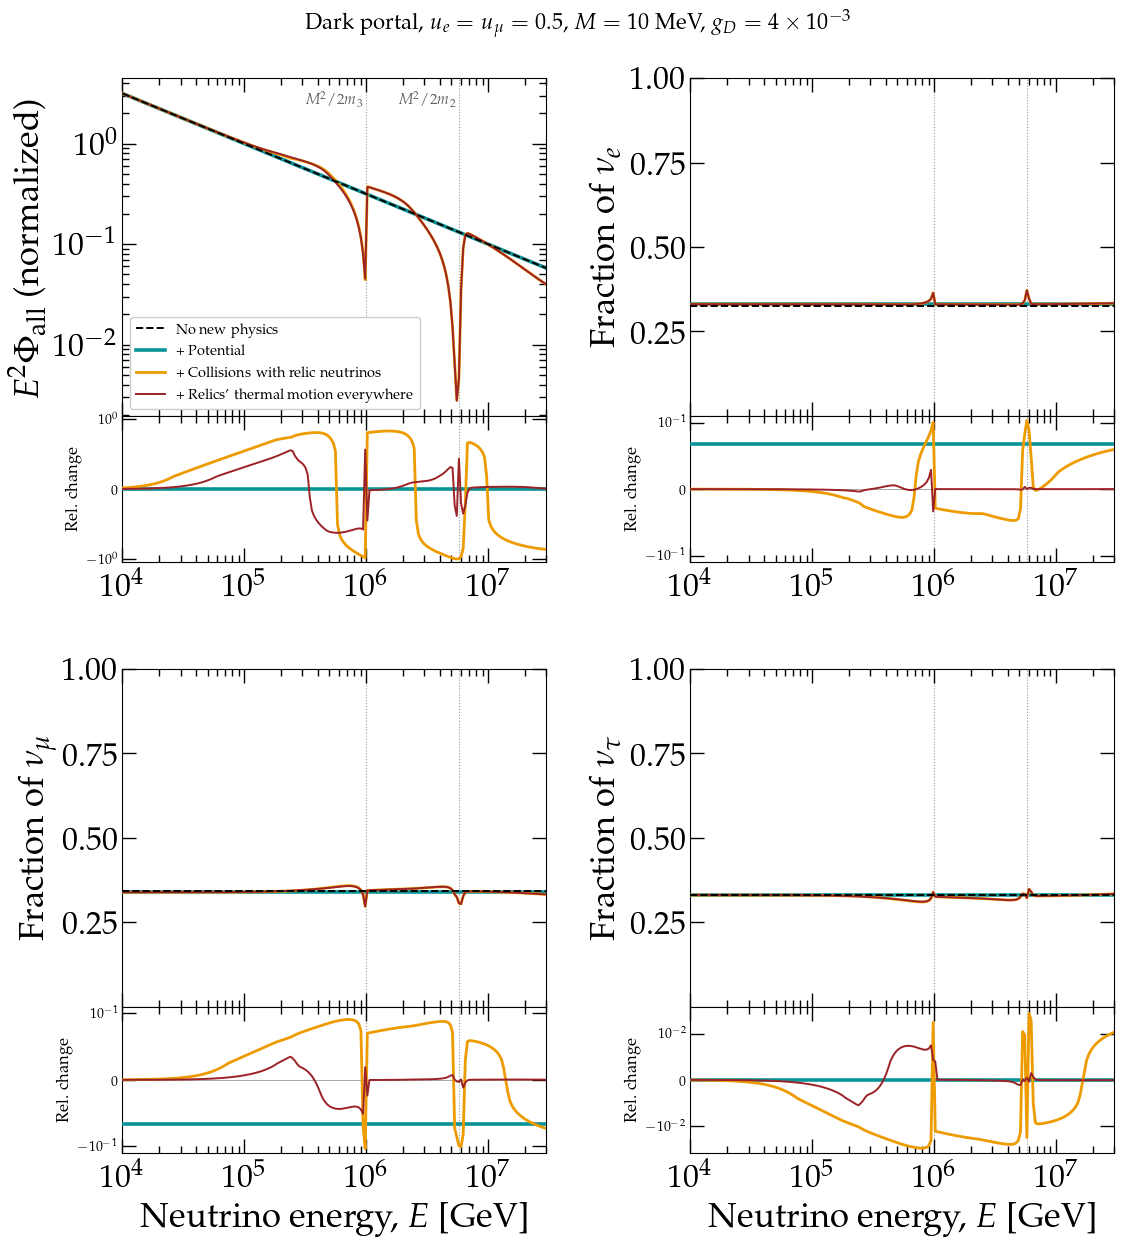

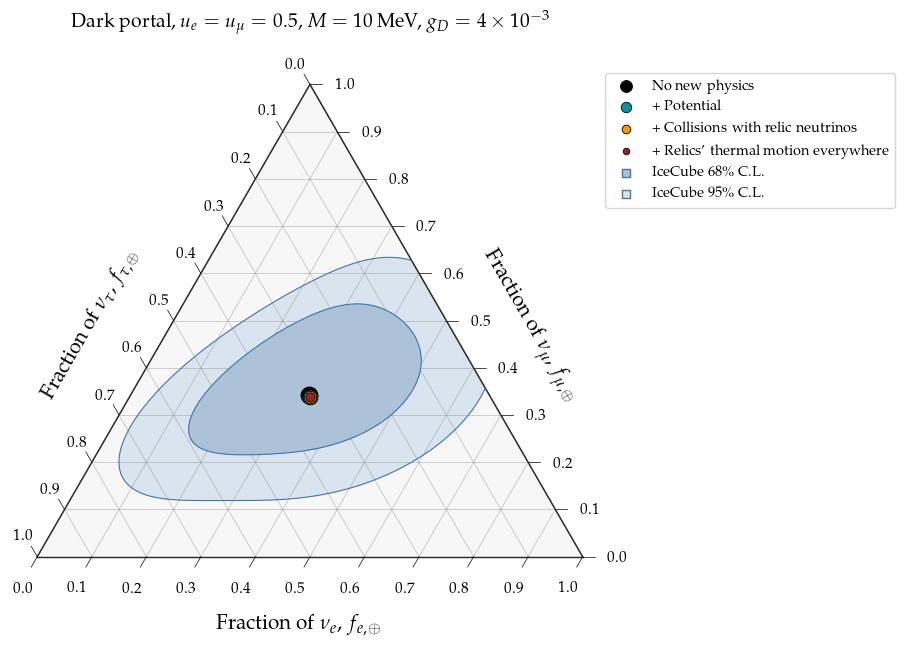

In [3]:
M_DP, G_DP = 1e7, 4e-3
DP = dict(model="dark_portal", m_eV=M_DP, g=G_DP, u_e=0.5, u_mu=0.5, epsilon_prime=1e-6)
dark_portal = dict(standard)
dark_portal.update(run_steps([
    ("+ Potential", dict(DP, collisions=False)),
    ("+ Collisions with relic neutrinos", DP),
    ("+ Relics' thermal motion everywhere", dict(DP, thermal=True)),
]))
# the resonance energies today on the two heavier relics (normal ordering, lightest mass M_LIGHTEST)
m2 = np.sqrt(M_LIGHTEST**2 + MIXING["dm21_sq"])
m3 = np.sqrt(M_LIGHTEST**2 + MIXING["dm31_sq"])
marks = [(M_DP**2 / (2 * m) / 1e9, lab) for m, lab in [(m3, r"$M^2/2m_3$"), (m2, r"$M^2/2m_2$")]]
print("Resonance energies today:", ", ".join(f"{E:.3g} GeV" for E, _ in marks))
title = r"Dark portal, $u_e = u_\mu = 0.5$, $M = 10$ MeV, $g_D = 4 \times 10^{-3}$"
fig = plot_steps(dark_portal, title, marks)
plt.show()
fig = plot_triangle(dark_portal, title)
plt.show()

**What you see.**

- **The potential acts only inside the Earth**, as for any MeV mediator: its range is $2 \times 10^{-14}$ m. There the
  dark portal's potential, proportional to $u u^\dagger$, mixes $\nu_e$ with $\nu_\mu$, so their fractions move toward
  each other: from 0.326 and 0.343 to 0.331 and 0.339. They do not meet, because neutrinos arriving from above cross
  only the ice.
- **Absorption carves two dips**, at the resonances on the two heavier relics. The one at 5.8 PeV removes nearly all
  the flux there.
- **Just below each dip the flux rises above the reference**: the secondaries of the absorbed neutrinos land there.
- **The flavors change only slightly** near the dips.
- **The relics' thermal motion** in every collision changes the flux by at most 4%, below the dip at 1 PeV, and
  the flavor fractions by at most 0.002.

### A $10^{-10}$ eV mediator

The sterile neutrino mixes with $\nu_\mu$ alone, $|u_\mu|^2 = 0.5$, with coupling $g_D = 2 \times 10^{-14}$, and
there is no Z mixing ($\epsilon' = 0$), so no potential. The mediator is far lighter than the neutrino mass
differences, so every heavier state can decay.

+ Decay                                       (f_e, f_mu, f_tau) = (0.534, 0.232, 0.234)   [1 s]


+ Soft scatterings on relic neutrinos         (f_e, f_mu, f_tau) = (0.534, 0.232, 0.234)   [1 s]


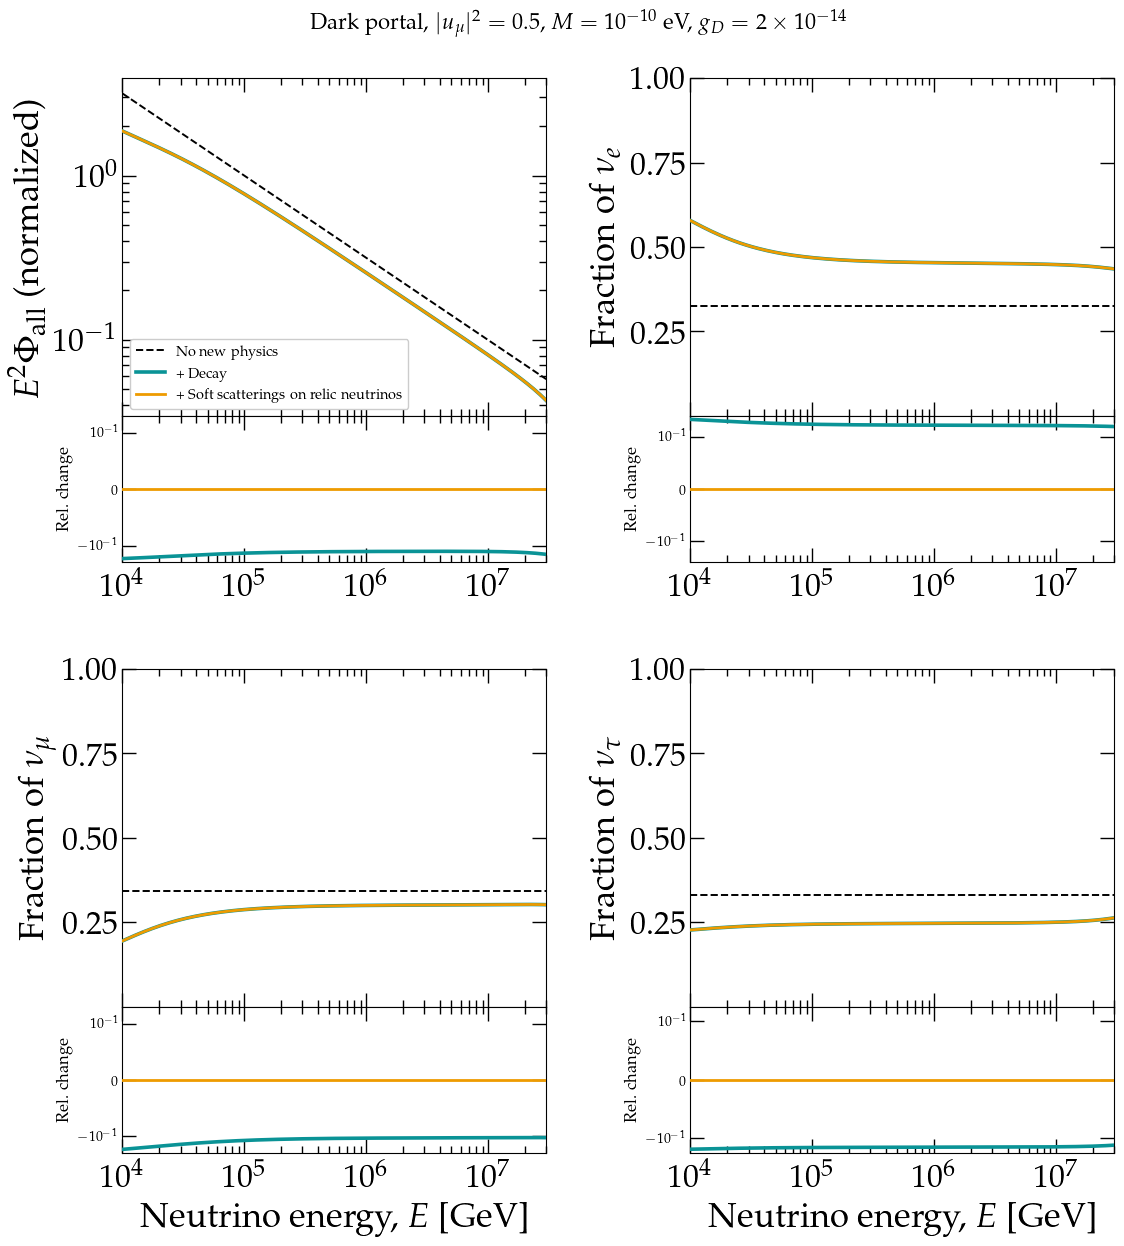

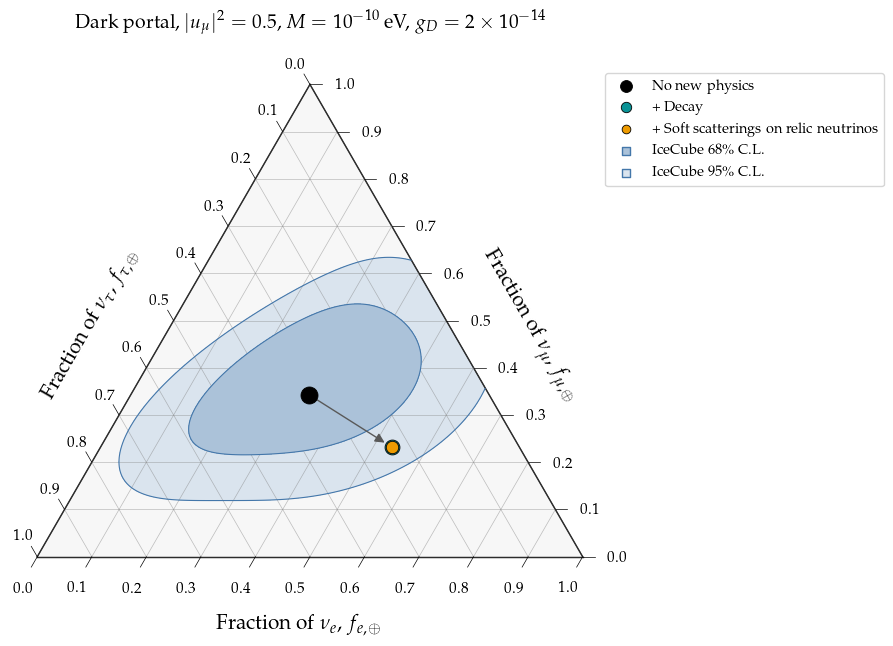

In [4]:
DPD = dict(model="dark_portal", m_eV=1e-10, g=2e-14, u_mu=np.sqrt(0.5))
dark_portal_decay = dict(standard)
dark_portal_decay.update(run_steps([
    ("+ Decay", dict(DPD, scattering=False)),
    ("+ Soft scatterings on relic neutrinos", DPD),
]))
title = r"Dark portal, $|u_\mu|^2 = 0.5$, $M = 10^{-10}$ eV, $g_D = 2 \times 10^{-14}$"
fig = plot_steps(dark_portal_decay, title)
plt.show()
fig = plot_triangle(dark_portal_decay, title)
plt.show()

**What you see.**

- **Decay lowers the flux** at every energy: by 41% at 10 TeV and by about 20% from 1 PeV up. The decays are faster
  at low energies, and the mediator carries off part of the energy.
- **Decay makes the flux richer in $\nu_e$.** The heavier states decay into $\nu_1$, which is mostly $\nu_e$: $f_e$ is
  0.58 at 10 TeV and 0.45 at 10 PeV.
- **Soft scatterings change nothing**: their rate grows as $g_D^4/M^2$, which is negligible at this coupling.

## 3. $L_e - L_\mu$

### A $10^{-20}$ eV mediator

Coupling $g' = 10^{-24}$. The mediator's range, about 130 AU, takes in the Sun. Near the Earth the potential comes
mostly from the Sun's electrons, and it is about $10^8$ times the vacuum oscillation term at 1 PeV.

The mediator is also light enough for the heavier neutrinos to decay into lighter ones.

+ Potential                                   (f_e, f_mu, f_tau) = (0.307, 0.307, 0.386)   [0 s]


+ Decay                                       (f_e, f_mu, f_tau) = (0.469, 0.469, 0.062)   [16 s]


+ Soft scatterings on relic neutrinos         (f_e, f_mu, f_tau) = (0.469, 0.469, 0.062)   [15 s]


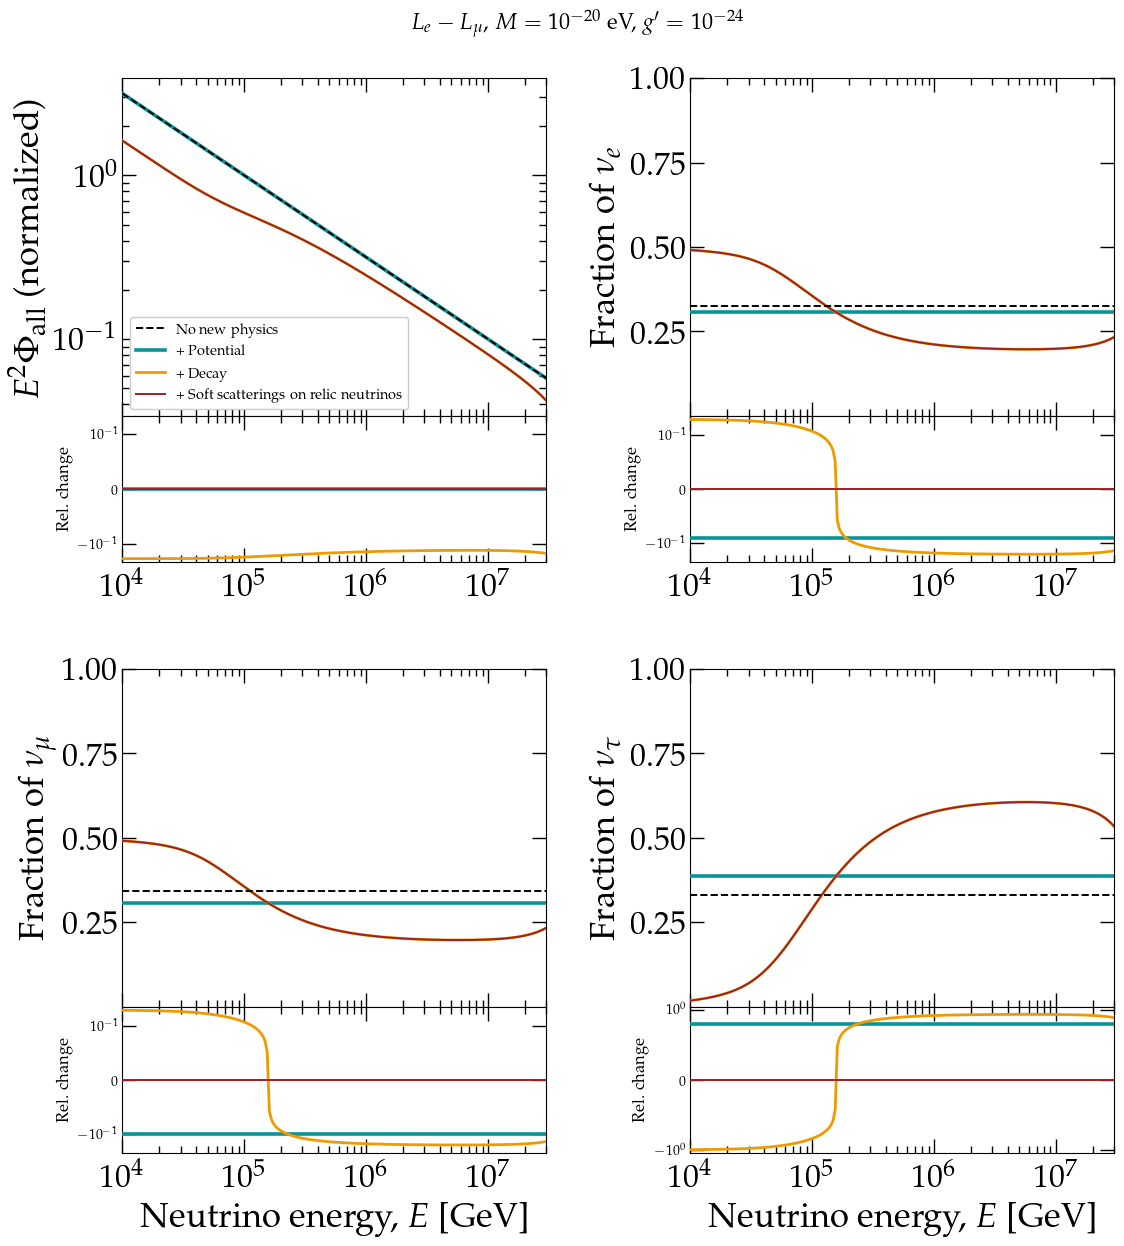

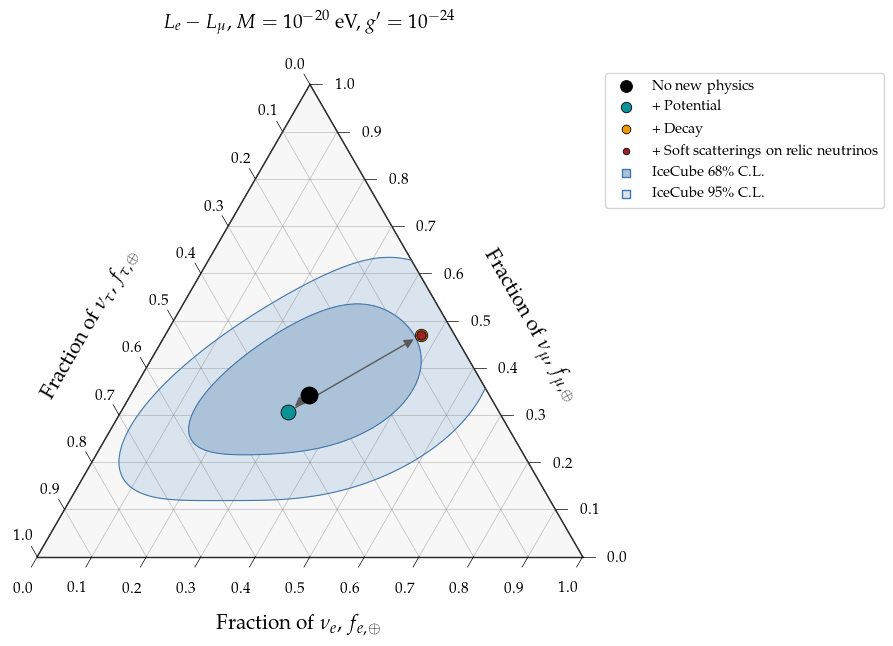

In [5]:
M_UL, G_UL = 1e-20, 1e-24
ultralight = dict(standard)
ultralight.update(run_steps([
    ("+ Potential", dict(model="L_e-L_mu", m_eV=M_UL, g=G_UL, collisions=False)),
    ("+ Decay", dict(model="L_e-L_mu", m_eV=M_UL, g=G_UL, scattering=False)),
    ("+ Soft scatterings on relic neutrinos", dict(model="L_e-L_mu", m_eV=M_UL, g=G_UL)),
]))
fig = plot_steps(ultralight, rf"$L_e - L_\mu$, $M = 10^{{-20}}$ eV, $g' = 10^{{-24}}$")
plt.show()
fig = plot_triangle(ultralight, rf"$L_e - L_\mu$, $M = 10^{{-20}}$ eV, $g' = 10^{{-24}}$")
plt.show()

**What you see.**

- **The potential turns each mass state into one flavor.** It rises slowly, over hundreds of AU, so the change is
  smooth. Neutrinos and antineutrinos feel it with opposite signs: $\nu_1$ becomes $\nu_\mu$ for one and $\nu_e$ for
  the other ($\nu_3$ the reverse), and $\nu_2$ becomes $\nu_\tau$ for both. So $f_\tau$ equals the share of $\nu_2$,
  0.386, and $f_e = f_\mu = 0.307$.
- **Decay empties the heavier states**, faster at lower energies. At 10 TeV nearly everything has reached $\nu_1$,
  which the potential turns into $(0.5, 0.5, 0)$. Between 1 and 10 PeV, $\nu_3$ has decayed partly into $\nu_2$, so
  $f_\tau$ rises to 0.6.
- **Decay also lowers the flux**, by half at 10 TeV, because the mediator carries off part of the energy.
- **Scatterings change nothing here.** Their rate grows as $g'^4/M^2$, which is far too small at this coupling.

### A $10^{-2}$ eV mediator

Coupling $g' = 10^{-6}$. Here only $\nu_3$ can decay: $m_3 - m_1 \approx 50$ meV is larger than the mediator's mass,
but $m_2 - m_1 \approx 8.7$ meV is not.

The coupling is large enough for soft scatterings on the relic neutrinos, which move neutrinos between states at nearly
the same energy.

+ Potential                                   (f_e, f_mu, f_tau) = (0.326, 0.343, 0.330)   [0 s]


+ Decay                                       (f_e, f_mu, f_tau) = (0.445, 0.307, 0.248)   [10 s]


+ Soft scatterings on relic neutrinos         (f_e, f_mu, f_tau) = (0.480, 0.277, 0.242)   [10 s]


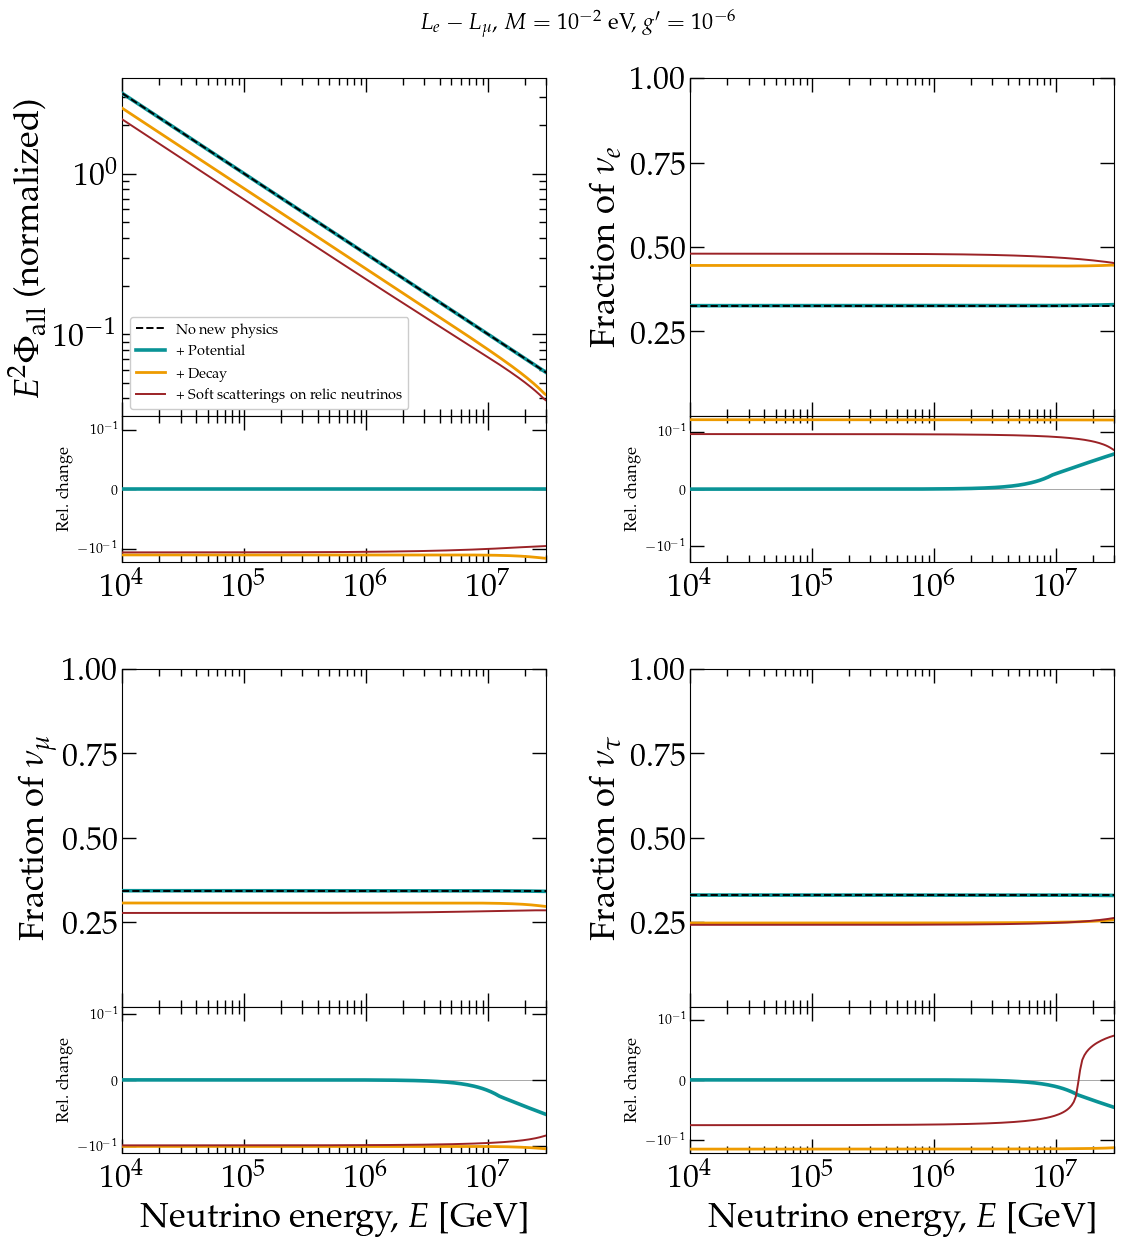

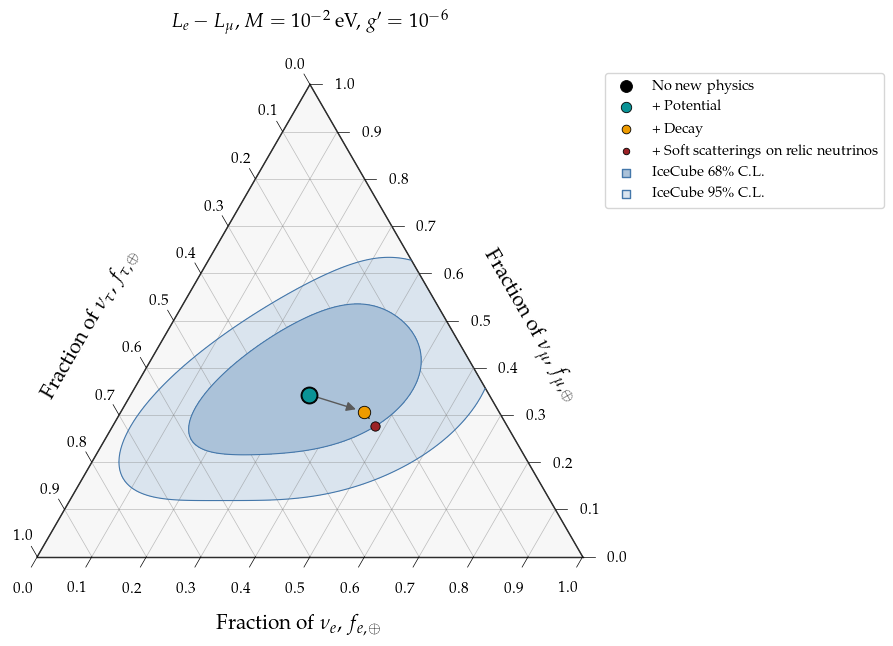

In [6]:
M_LIGHT, G_LIGHT = 1e-2, 1e-6
light = dict(standard)
light.update(run_steps([
    ("+ Potential", dict(model="L_e-L_mu", m_eV=M_LIGHT, g=G_LIGHT, collisions=False)),
    ("+ Decay", dict(model="L_e-L_mu", m_eV=M_LIGHT, g=G_LIGHT, scattering=False)),
    ("+ Soft scatterings on relic neutrinos", dict(model="L_e-L_mu", m_eV=M_LIGHT, g=G_LIGHT)),
]))
fig = plot_steps(light, rf"$L_e - L_\mu$, $M = 10^{{-2}}$ eV, $g' = 10^{{-6}}$")
plt.show()
fig = plot_triangle(light, rf"$L_e - L_\mu$, $M = 10^{{-2}}$ eV, $g' = 10^{{-6}}$")
plt.show()

**What you see.**

- **The potential changes the flavors by about 1%, above 10 PeV.** Its range is only 20 $\mu$m, so it comes from the
  matter right around the neutrinos. Near the Sun, the Milky Way's matter makes a potential that is no longer
  negligible against the vacuum term, which falls with energy.
- **Decay empties $\nu_3$** into $\nu_1$ and $\nu_2$. The flux drops by about 20%, and $f_e$ rises from 0.33 to 0.45.
- **Scatterings alone would keep the flux**: they only move neutrinos between states. Here they keep refilling
  $\nu_3$, which keeps decaying. The flux drops to about 70% of the reference, and the flavors move further toward
  those of $\nu_1$ ($f_e = 0.48$).

At larger couplings this cycle removes most of the flux: to 6% at $g' = 3 \times 10^{-6}$, and to 0.05% at
$10^{-5}$. How much is really lost depends on the mediator. The code treats it as invisible, but it can decay back
into the lightest neutrinos; this is still an open question.

## 4. Secret interactions

### A 10 MeV scalar

The mediator is a scalar of 10 MeV, coupled to $\nu_\tau$ alone with strength $g = 10^{-3}$. It makes no potential,
so the steps are the collisions: first the resonance alone (the $s$ channel), then every channel, then the relics'
thermal motion (by default, secret interactions treat the relics as at rest).

+ Resonance ($s$ channel)                     (f_e, f_mu, f_tau) = (0.326, 0.343, 0.331)   [0 s]


+ Every channel                               (f_e, f_mu, f_tau) = (0.326, 0.343, 0.331)   [0 s]


+ Relics' thermal motion everywhere           (f_e, f_mu, f_tau) = (0.326, 0.343, 0.331)   [1 s]


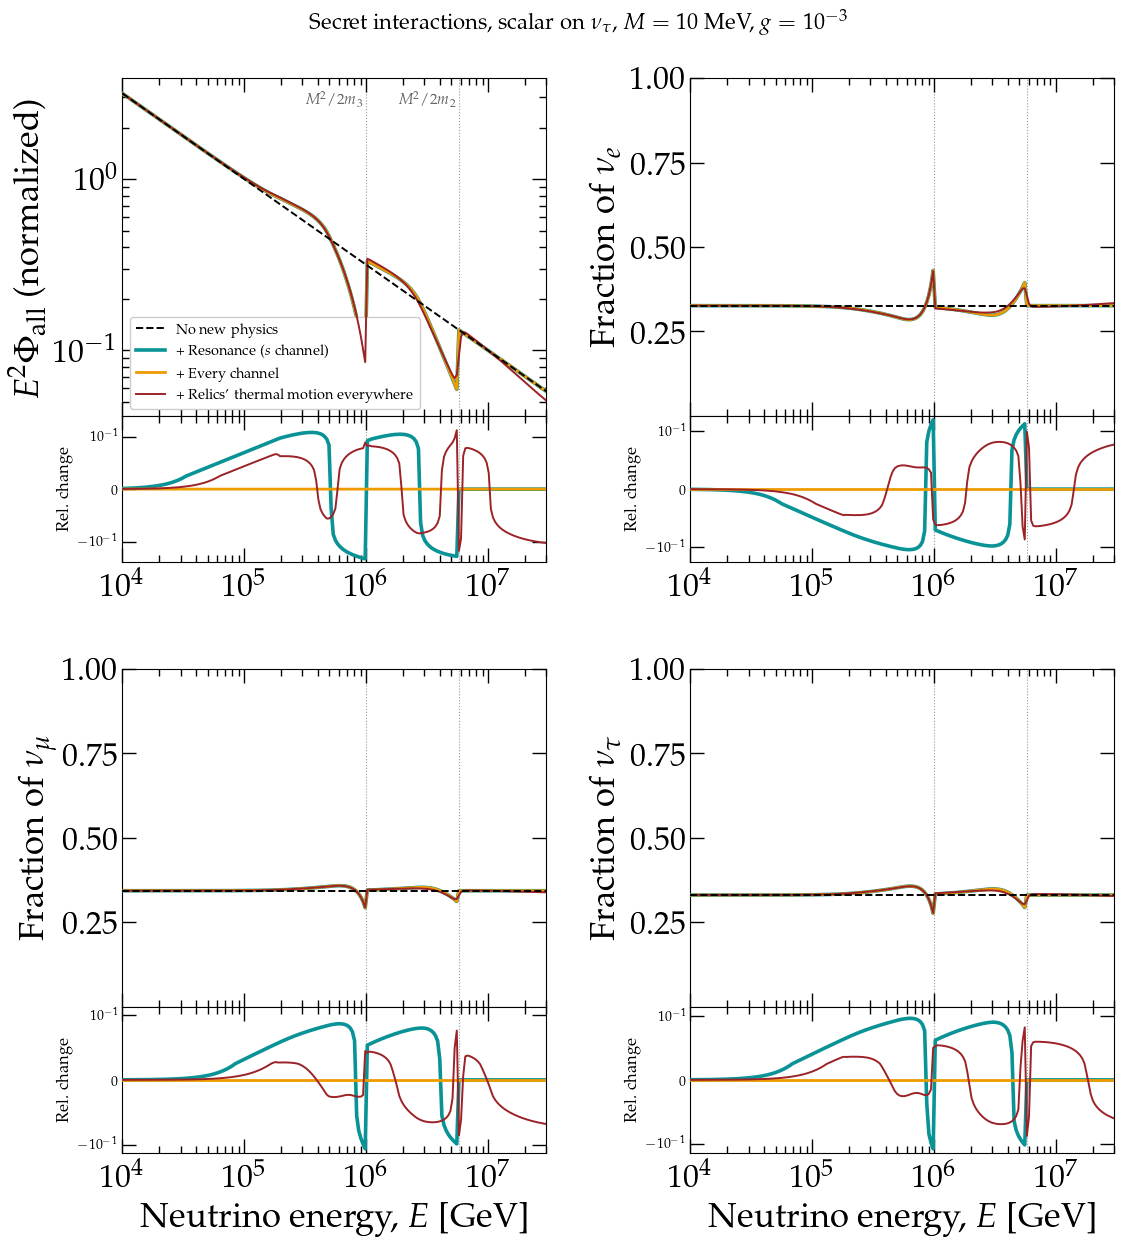

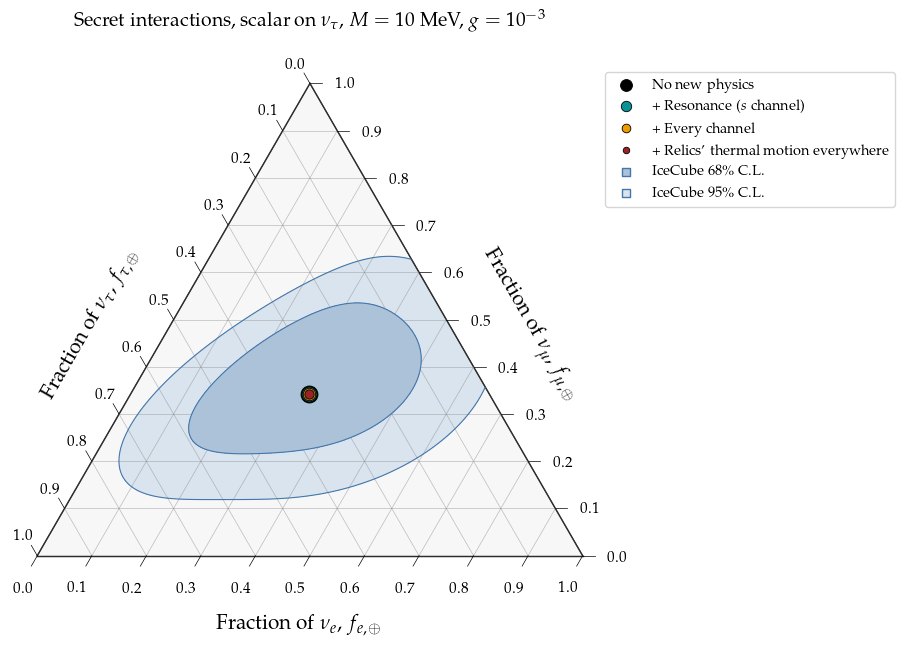

In [7]:
M_SI, G_SI = 1e7, 1e-3
secret = dict(standard)
secret.update(run_steps([
    ("+ Resonance ($s$ channel)", dict(si=True, m_eV=M_SI, g=G_SI, channels="s")),
    ("+ Every channel", dict(si=True, m_eV=M_SI, g=G_SI)),
    ("+ Relics' thermal motion everywhere", dict(si=True, m_eV=M_SI, g=G_SI, thermal=True)),
]))
marks = [(M_SI**2 / (2 * m) / 1e9, lab) for m, lab in [(m3, r"$M^2/2m_3$"), (m2, r"$M^2/2m_2$")]]
title = r"Secret interactions, scalar on $\nu_\tau$, $M = 10$ MeV, $g = 10^{-3}$"
fig = plot_steps(secret, title, marks)
plt.show()
fig = plot_triangle(secret, title)
plt.show()

**What you see.**

- **The resonance makes the dips**, at the same energies as for the dark portal: they depend only on the mediator's
  mass and the relics' masses. Below each dip, the secondaries pile up above the reference.
- **The other channels change the flux by less than 0.05%** at this mass and coupling.
- **The flavors change near the dips.** The scalar couples only to $\nu_\tau$, so it absorbs most the mass states
  with the most $\nu_\tau$, $\nu_3$ and $\nu_2$. What survives is richer in $\nu_1$, which is mostly $\nu_e$, so $f_e$
  rises there.
- **The relics' thermal motion matters**: it changes the flux by up to 30%, at the sharp upper edge of the dip at
  5.8 PeV, which the relics' motion smears, and the flavor fractions by up to 0.03.

### A 1 meV scalar

The scalar has a mass of 1 meV, lighter than both neutrino mass differences, so $\nu_3$ and $\nu_2$ can decay. It
couples to $\nu_\tau$ with $g = 10^{-6}$.

+ Decay                                       (f_e, f_mu, f_tau) = (0.567, 0.204, 0.229)   [0 s]
+ Soft scatterings on relic neutrinos         (f_e, f_mu, f_tau) = (0.567, 0.204, 0.229)   [0 s]


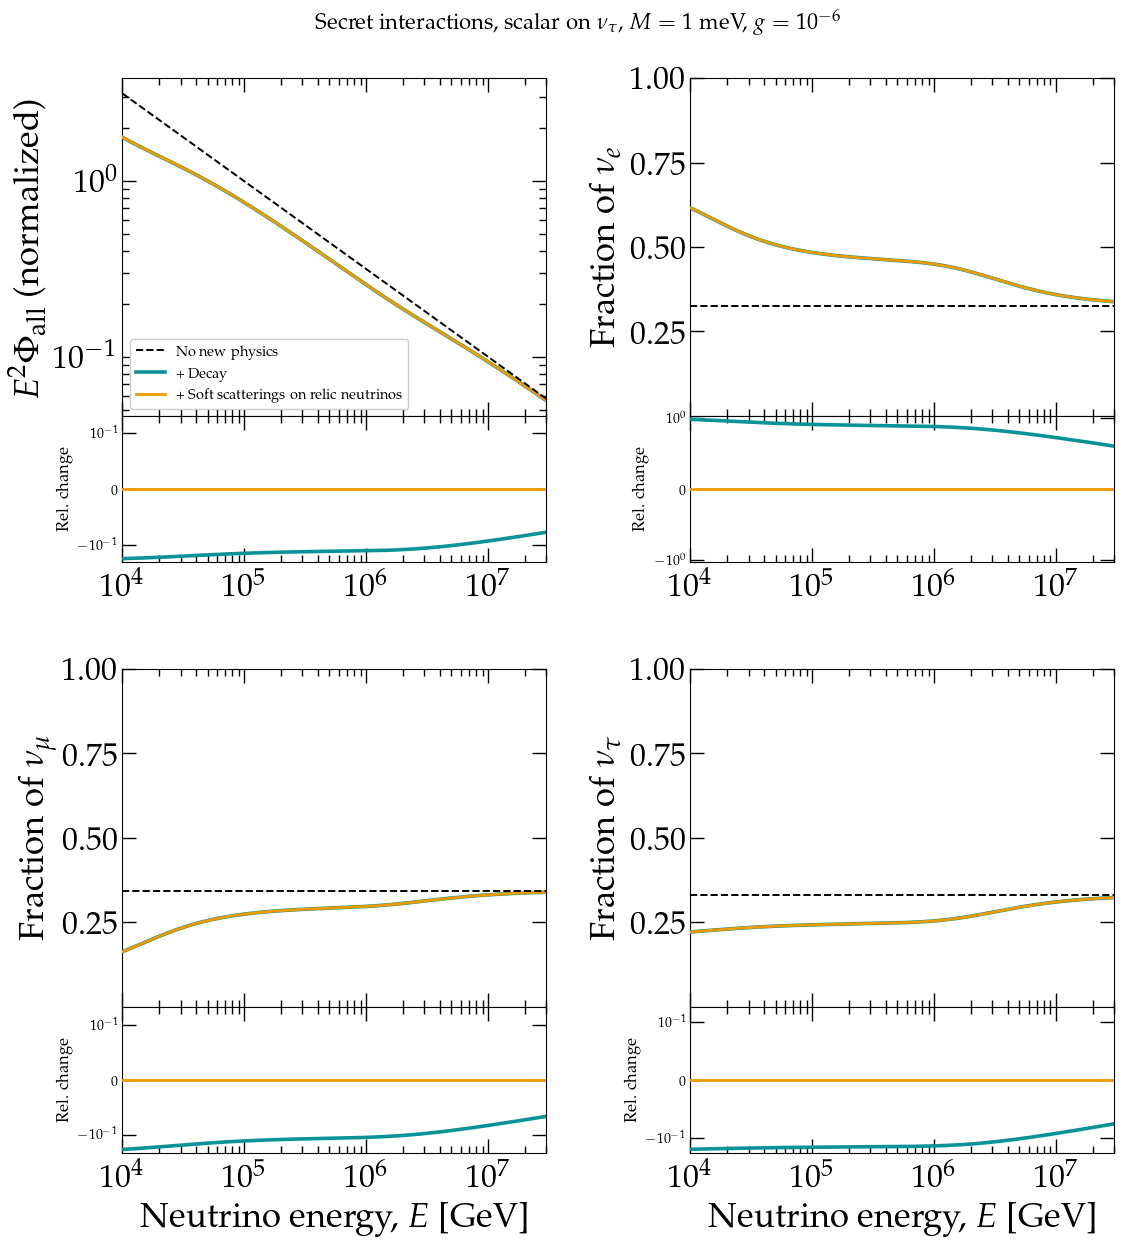

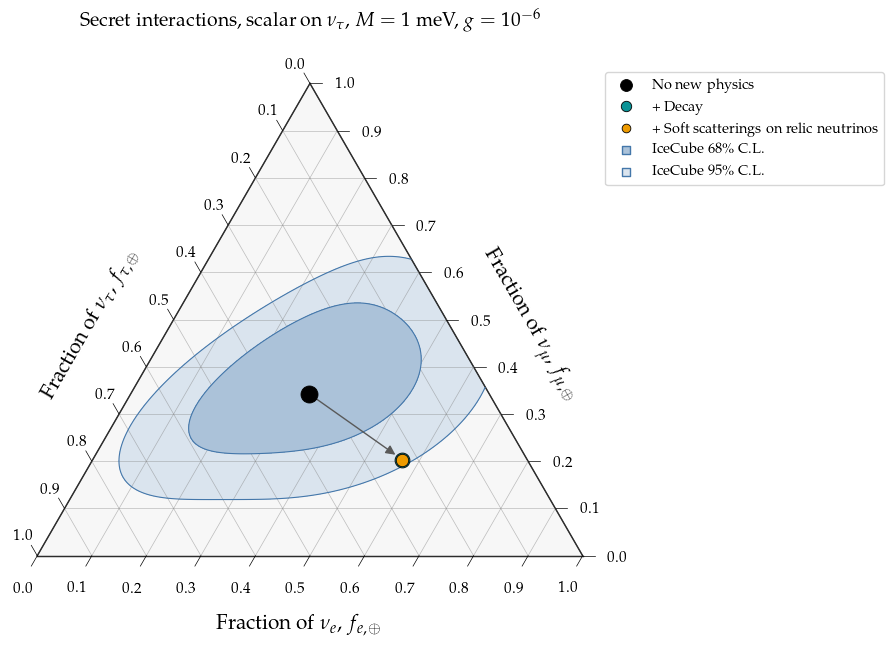

In [8]:
SID = dict(si=True, m_eV=1e-3, g=1e-6)
secret_decay = dict(standard)
secret_decay.update(run_steps([
    ("+ Decay", dict(SID, scattering=False)),
    ("+ Soft scatterings on relic neutrinos", SID),
]))
title = r"Secret interactions, scalar on $\nu_\tau$, $M = 1$ meV, $g = 10^{-6}$"
fig = plot_steps(secret_decay, title)
plt.show()
fig = plot_triangle(secret_decay, title)
plt.show()

**What you see.**

- **Decay lowers the flux**: by 44% at 10 TeV, 19% at 1 PeV and 6% at 10 PeV, where few neutrinos have time to
  decay.
- **Decay makes the flux richer in $\nu_e$.** $\nu_3$ and $\nu_2$ decay into $\nu_1$, which is mostly $\nu_e$: $f_e$
  is 0.62 at 10 TeV and 0.36 at 10 PeV.
- **Soft scatterings change nothing** at this coupling.

## 5. The trip, stop by stop

The $10^{-20}$ eV $L_e - L_\mu$ example of Section 3, with every effect on, seen at four stops on the way: arriving at the Milky Way
(the extragalactic flux), after crossing the Milky Way, near the Earth after the Sun, and at the detector after the
Earth. At each stop, the flux is what a detector there would see.

Arriving at the Milky Way           (f_e, f_mu, f_tau) = (0.653, 0.132, 0.216), total 20.21
After the Milky Way                 (f_e, f_mu, f_tau) = (0.653, 0.132, 0.216), total 20.21
Near the Earth, after the Sun       (f_e, f_mu, f_tau) = (0.469, 0.469, 0.062), total 20.21
At the detector, after the Earth    (f_e, f_mu, f_tau) = (0.469, 0.469, 0.062), total 20.21
[29 s]


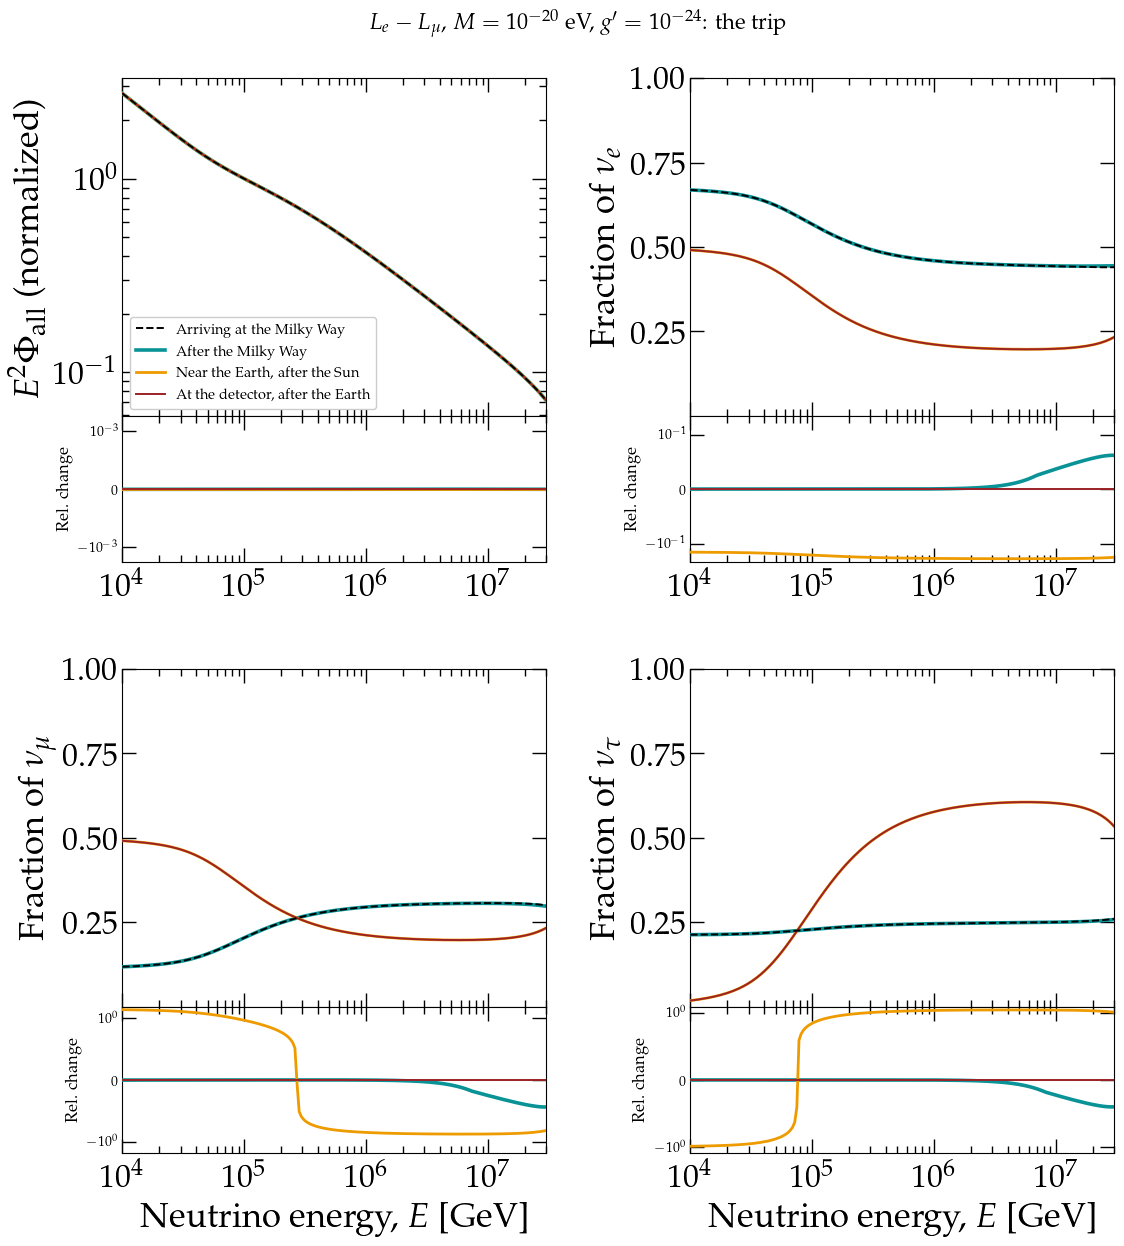

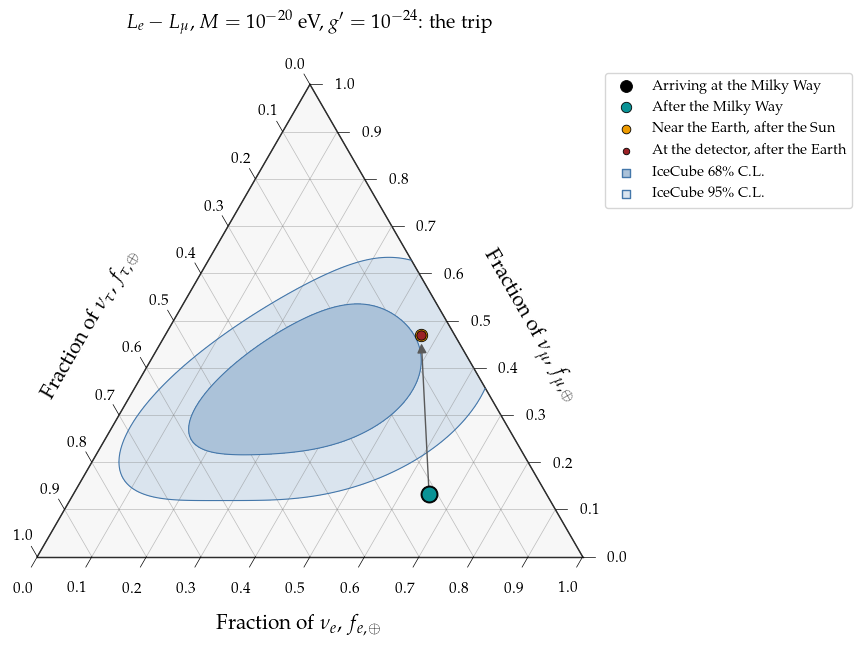

In [9]:
NAMES = {"universe": "Arriving at the Milky Way", "galaxy": "After the Milky Way",
         "earth": "Near the Earth, after the Sun", "detector": "At the detector, after the Earth"}


def trip(model, m_eV, g, title):
    # the flux at the four stops of the trip (dark_portal_solver.flux_stops), printed and plotted
    E, params = solver_params(model, m_eV, g)
    t = time.time()
    stops = dps.flux_stops(E, params)
    out = {NAMES[k]: (E / 1e9, F) for k, F in stops.items()}
    for label, (Eg, F) in out.items():
        f = compute_energy_averaged_ratios(Eg * 1e9, F)
        print(f"{label:35s} (f_e, f_mu, f_tau) = ({f[0]:.3f}, {f[1]:.3f}, {f[2]:.3f}), total {F.sum():.4g}")
    print(f"[{time.time() - t:.0f} s]")
    plot_steps(out, title)
    plt.show()
    plot_triangle(out, title)
    plt.show()
    return out


trip_20 = trip("L_e-L_mu", M_UL, G_UL, rf"$L_e - L_\mu$, $M = 10^{{-20}}$ eV, $g' = 10^{{-24}}$: the trip")

**What you see at $10^{-20}$ eV.**

- **Arriving at the Milky Way**, the decays have left mostly $\nu_1$ at low energies, whose flavors are
  $(0.68, 0.11, 0.21)$, and a mix of $\nu_1$ and $\nu_2$ at high energies.
- **The Milky Way changes nothing** at this mass: its potential is too weak, and almost no neutrino decays while
  crossing it.
- **Near the Earth, the Sun's potential** turns each mass state into one flavor, as in Section 3.
- **The Earth changes nothing more**: its potential has the same flavor structure as the Sun's.
- **The total flux is the same at every stop**: after the Universe, the trip only moves neutrinos between flavors.

Which body does the work depends on the mediator's mass, through its range. At $10^{-26}$ eV the Milky Way's
potential does what the Sun does here. At 10 MeV all four stops coincide, because the potential acts only inside the
Earth.

### The same at $10^{-26}$ eV

At $10^{-26}$ eV the mediator's range is about 600 pc, and the Milky Way's potential matters. It dominates only at
couplings where the decays are strong, so this example has $g' = 10^{-27}$.

Arriving at the Milky Way           (f_e, f_mu, f_tau) = (0.676, 0.112, 0.212), total 19.32
After the Milky Way                 (f_e, f_mu, f_tau) = (0.961, 0.034, 0.005), total 11.29
Near the Earth, after the Sun       (f_e, f_mu, f_tau) = (0.964, 0.035, 0.002), total 11.29
At the detector, after the Earth    (f_e, f_mu, f_tau) = (0.964, 0.035, 0.002), total 11.29
[63 s]


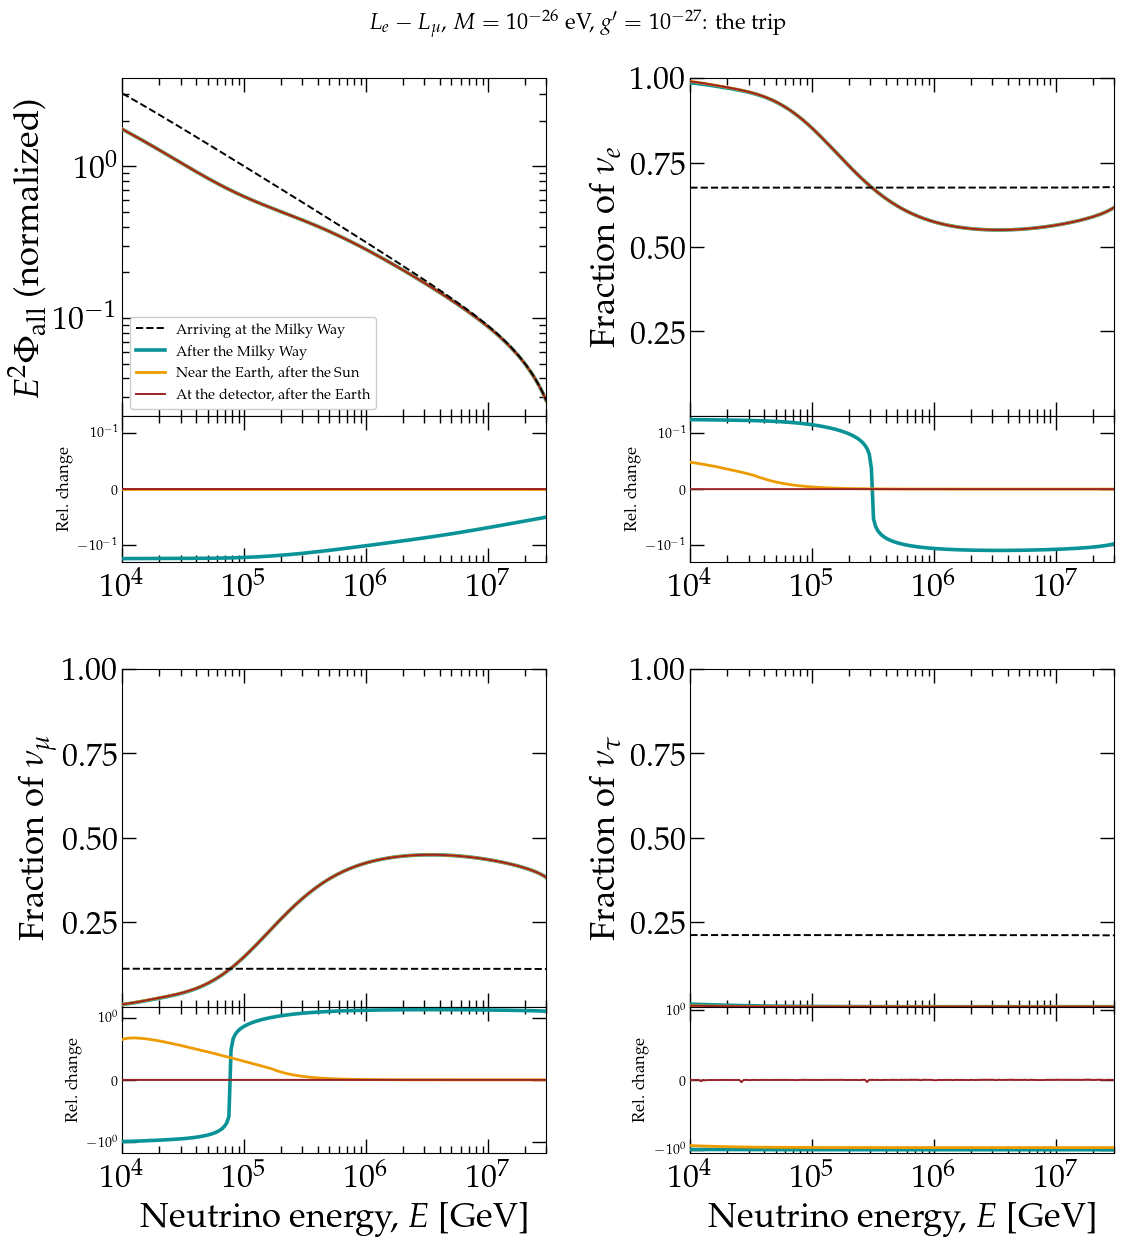

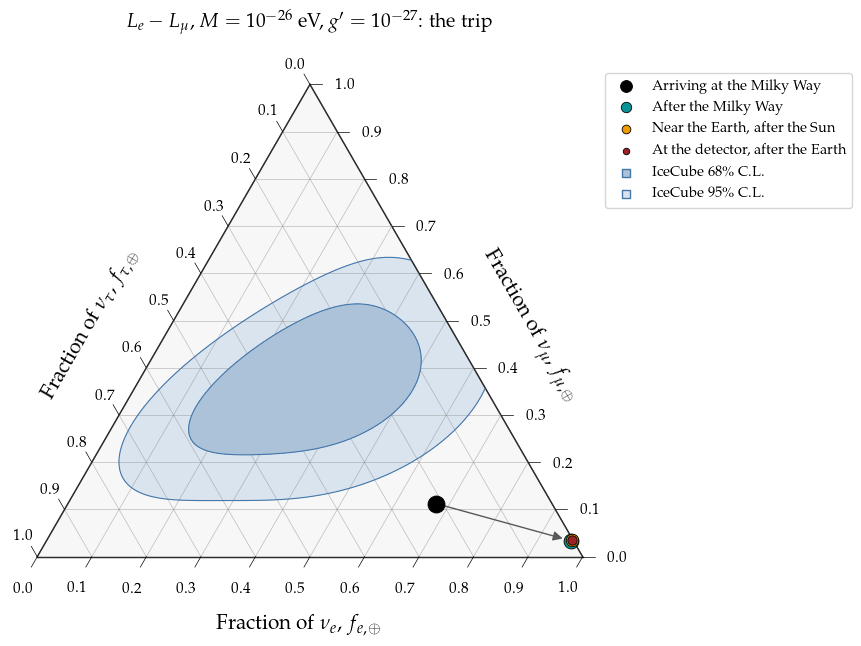

In [10]:
trip_26 = trip("L_e-L_mu", 1e-26, 1e-27, rf"$L_e - L_\mu$, $M = 10^{{-26}}$ eV, $g' = 10^{{-27}}$: the trip")

**What you see at $10^{-26}$ eV.**

- **Arriving at the Milky Way**, the decays have left pure $\nu_1$: $(0.68, 0.11, 0.21)$.
- **In the Milky Way**, the potential turns each mass state into one flavor, as the Sun does at $10^{-20}$ eV. It also
  gives the lightest neutrino state and the lightest antineutrino state different energies, so the heavier of the two
  decays into the lighter one. Between galaxies they have the same mass and cannot.
- **At high energies these decays are incomplete**, and the flavors are close to $(0.5, 0.5, 0)$. At low energies they
  are complete, and only $\nu_e$ and $\bar\nu_e$ are left.
- **The decays lower the flux**, by about 40% in total and most at low energies, because the mediator carries off part
  of the energy.
- **The Sun and the Earth** change almost nothing more.

## 6. Trying your own case

Copy the pattern of the examples into a new cell. For instance, $L_e - L_\tau$ with a $10^{-18}$ eV mediator:

```python
mine = dict(standard)
mine.update(run_steps([
    ("+ Potential", dict(model="L_e-L_tau", m_eV=1e-18, g=1e-25, collisions=False)),
    ("+ Decay", dict(model="L_e-L_tau", m_eV=1e-18, g=1e-25, scattering=False)),
]))
plot_steps(mine, "My case")
plt.show()
```

`flux_at_earth` takes any model of `src/dp_models.py`, and `si_flux` takes secret interactions. Each step takes from
a second to half a minute on 4 cores; the decays at large couplings take longest. `trip(model, m_eV, g, title)`
shows the stops of the trip for any model but secret interactions.